# Supplementary Fig S9 · The block distance follows the whole-matrix distance

Breast, the three largest niches of the seed-0 layout, 1,000 random pairs of index tiles per niche (both tiles in the
same niche, so they share its gene order and blocks).

* **A–C** one niche each: the block distance d_B against the whole-matrix log-Euclidean distance d_W of each pair;
  dashed y = x; Spearman and Pearson correlation.
* **D–F** below it, on the same x axis: the gap d_W − d_B of each pair; dashed zero, solid the median gap.

**Run first:** `R12_block_distance` (`results/block_distance/pairs.csv`, `niches.csv`).
Writes `figures/figS9_block_distance/` (manuscript: `FigS9_block_distance.pdf`).

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datasets.yaml").exists())
sys.path.insert(0, str(ROOT / "experiments" / "common"))
import numpy as np
import pandas as pd
from matplotlib.ticker import MultipleLocator
from scipy.stats import pearsonr, spearmanr

import style as ps

FIG = "figS9_block_distance"
RES = ROOT / "results" / "block_distance"
PW, PH, DH = 60.0, 62.0, 44.0   # mm: column; scatter panel (square 47 mm axes); gap panel below
L, R = 11.0, 2.0                # mm: axes margins inside a column
DASH, DLW = (0, (3, 2)), 0.6     # y = x and zero lines: dash pattern, width (pt)

pairs = pd.read_csv(RES / "pairs.csv")
niches = pd.read_csv(RES / "niches.csv").set_index("niche")
order = list(niches.index)                      # largest first
colors = {k: ps.niche_palette(k + 1)[k] for k in order}  # niche i always gets colour i
print(sorted(set(pairs.tag)), niches.to_dict("index"))

['method-v2'] {0: {'tiles': 664, 'blocks': 16, 'p': 313, 'key': 'breast_cancer', 'tag': 'method-v2'}, 1: {'tiles': 493, 'blocks': 15, 'p': 313, 'key': 'breast_cancer', 'tag': 'method-v2'}, 2: {'tiles': 411, 'blocks': 17, 'p': 313, 'key': 'breast_cancer', 'tag': 'method-v2'}}


## A–C · d_B against d_W, one niche each

figures/figS9_block_distance/panels/A.pdf/.png: 60 x 62 mm, 0.0 / 0.4 MB
figures/figS9_block_distance/panels/B.pdf/.png: 60 x 62 mm, 0.0 / 0.4 MB
figures/figS9_block_distance/panels/C.pdf/.png: 60 x 62 mm, 0.0 / 0.4 MB


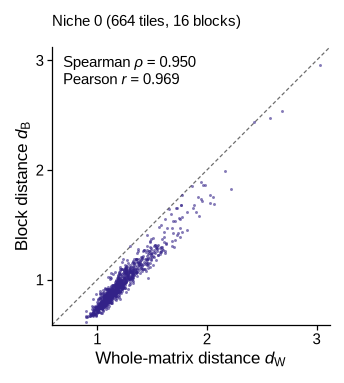

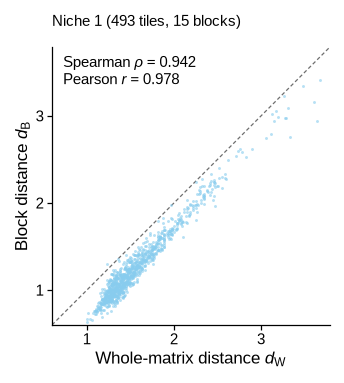

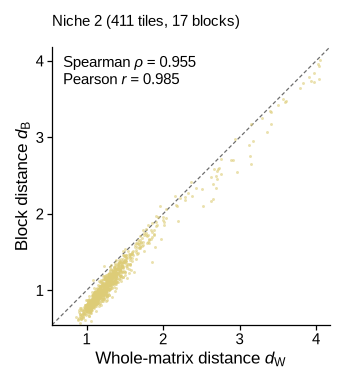

In [2]:
def limits(g):
    return 0.95 * min(g.d_whole.min(), g.d_block.min()), 1.03 * max(g.d_whole.max(), g.d_block.max())


def panel_scatter(fig, k):
    g = pairs[pairs.niche == k]
    ax = ps.axes(fig, left=L, bottom=9, right=R, top=6)
    lo, hi = limits(g)
    ax.plot([lo, hi], [lo, hi], color=ps.MUTED, lw=DLW, ls=DASH, zorder=1)
    ax.scatter(g.d_whole, g.d_block, s=2, lw=0, alpha=0.6, color=colors[k], zorder=2)
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect("equal")
    ax.xaxis.set_major_locator(MultipleLocator(1)); ax.yaxis.set_major_locator(MultipleLocator(1))
    ax.set_xlabel("Whole-matrix distance $d_{\\mathrm{W}}$")
    ax.set_ylabel("Block distance $d_{\\mathcal{B}}$")
    rho, r = spearmanr(g.d_whole, g.d_block)[0], pearsonr(g.d_whole, g.d_block)[0]
    ax.text(0.04, 0.97, f"Spearman $\\rho$ = {rho:.3f}\nPearson $r$ = {r:.3f}",
            transform=ax.transAxes, va="top", ha="left", fontsize=ps.TICK_PT)
    W_, H_ = ps.size_mm(fig)
    n = niches.loc[k]
    fig.text(L / W_, 1 - 0.5 / H_, f"Niche {k} ({n.tiles:,} tiles, {n.blocks} blocks)",
             ha="left", va="top", fontsize=ps.TICK_PT)


for letter, k in zip("ABC", order):
    fig = ps.panel(PW, PH); panel_scatter(fig, k); ps.save_panel(fig, FIG, letter)

## D–F · the gap d_W − d_B

niche 0: median gap 0.255, d_B <= d_W in 99.7 % of pairs
figures/figS9_block_distance/panels/D.pdf/.png: 60 x 44 mm, 0.0 / 0.4 MB
niche 1: median gap 0.300, d_B <= d_W in 99.7 % of pairs
figures/figS9_block_distance/panels/E.pdf/.png: 60 x 44 mm, 0.0 / 0.3 MB
niche 2: median gap 0.195, d_B <= d_W in 98.0 % of pairs
figures/figS9_block_distance/panels/F.pdf/.png: 60 x 44 mm, 0.0 / 0.3 MB


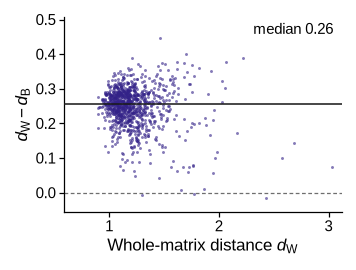

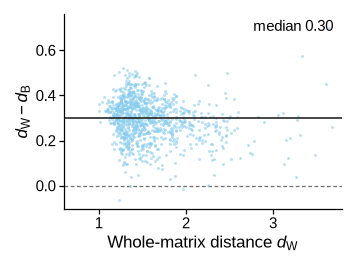

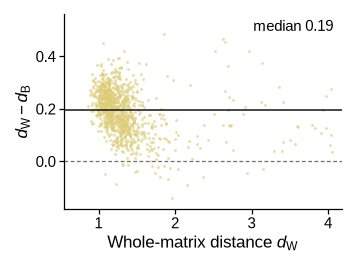

In [3]:
def panel_gap(fig, k):
    g = pairs[pairs.niche == k]
    gap = g.d_whole - g.d_block
    ax = ps.axes(fig, left=L, bottom=9, right=R, top=2)
    lo, hi = limits(g)
    ax.axhline(0, color=ps.MUTED, lw=DLW, ls=DASH, zorder=1)
    ax.scatter(g.d_whole, gap, s=2, lw=0, alpha=0.6, color=colors[k], zorder=2)
    m = float(np.median(gap))
    ax.axhline(m, color=ps.INK, lw=ps.LW, zorder=3)
    ax.set_xlim(lo, hi); ax.set_ylim(min(0.0, gap.min()) - 0.04, gap.max() + 0.06)  # room for the median label
    ax.xaxis.set_major_locator(MultipleLocator(1))
    ax.set_xlabel("Whole-matrix distance $d_{\\mathrm{W}}$")
    ax.set_ylabel("$d_{\\mathrm{W}} - d_{\\mathcal{B}}$")
    ax.text(0.97, 0.97, f"median {m:.2f}", transform=ax.transAxes, va="top", ha="right", fontsize=ps.TICK_PT)
    print(f"niche {k}: median gap {m:.3f}, d_B <= d_W in {100 * np.mean(gap >= 0):.1f} % of pairs")


for letter, k in zip("DEF", order):
    fig = ps.panel(PW, DH); panel_gap(fig, k); ps.save_panel(fig, FIG, letter)

## Full figure

niche 0: median gap 0.255, d_B <= d_W in 99.7 % of pairs
niche 1: median gap 0.300, d_B <= d_W in 99.7 % of pairs
niche 2: median gap 0.195, d_B <= d_W in 98.0 % of pairs
figures/figS9_block_distance/figS9_block_distance.pdf/.png: 180 x 106 mm, 0.1 / 2.4 MB


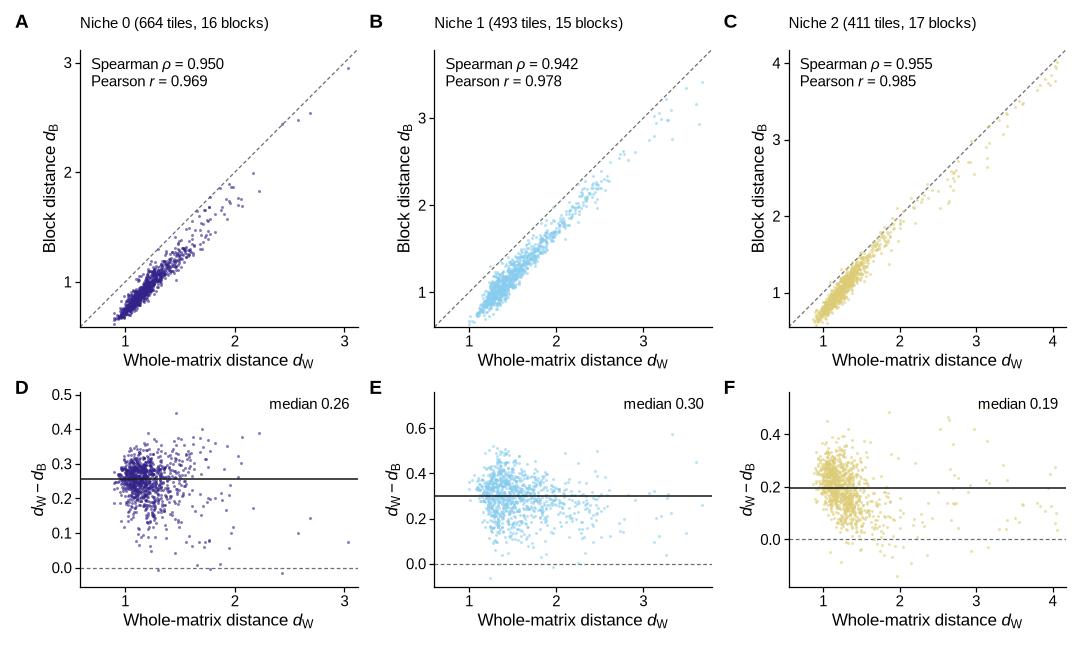

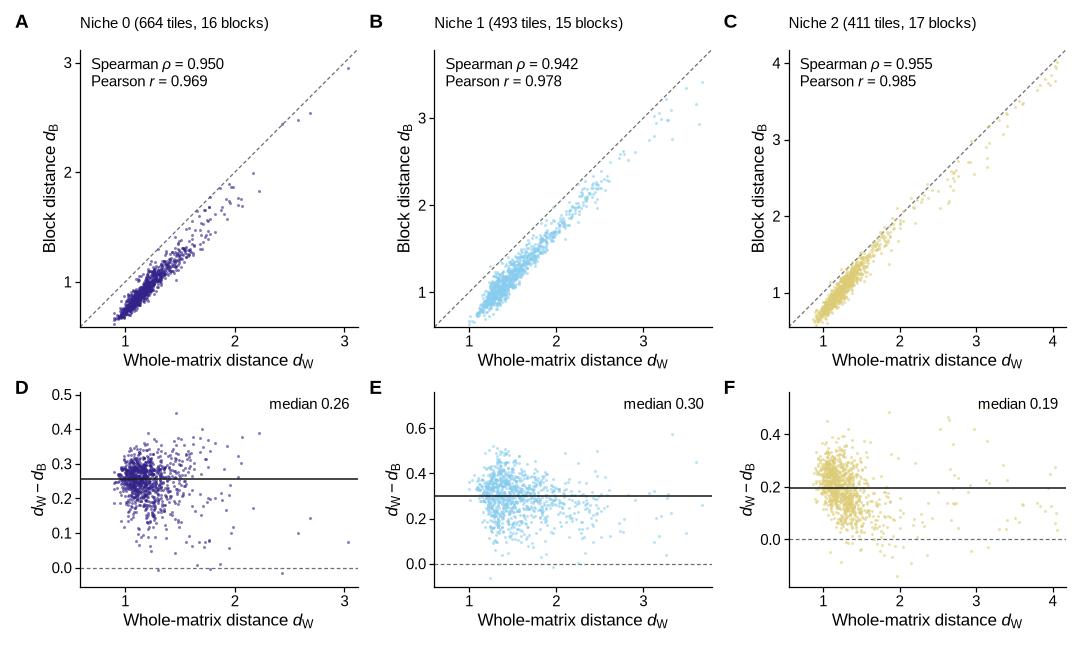

In [4]:
page = ps.page(3 * PW, PH + DH)
for i, (a, d, k) in enumerate(zip("ABC", "DEF", order)):
    panel_scatter(ps.place(page, a, x=i * PW, y=0, w=PW, h=PH), k)
    panel_gap(ps.place(page, d, x=i * PW, y=PH, w=PW, h=DH), k)
ps.save_figure(page, FIG)
page